In [2]:
!pip install -q ultralytics opencv-python matplotlib

In [3]:
import cv2
import os
import matplotlib.pyplot as plt

from pathlib import Path
from ultralytics import YOLO, solutions
from google.colab import files


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [4]:
uploaded = files.upload()

video_path = list(uploaded.keys())[0]

print("Uploaded video:", video_path)

Saving 10297623-hd_2160_3840_30fps.mp4 to 10297623-hd_2160_3840_30fps.mp4
Uploaded video: 10297623-hd_2160_3840_30fps.mp4


In [5]:
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print("Error: Cannot open video")
else:
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    print("Video opened successfully!")
    print("Width:", width)
    print("Height:", height)
    print("FPS:", fps)
    print("Total frames:", total_frames)
    print("Duration (seconds):", total_frames / fps if fps else 0)

cap.release()

Video opened successfully!
Width: 2160
Height: 3840
FPS: 29.97002997002997
Total frames: 624
Duration (seconds): 20.820800000000002


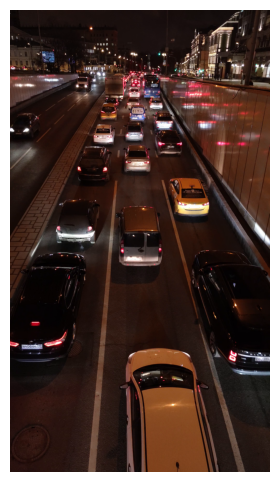

In [6]:
cap = cv2.VideoCapture(video_path)

success, frame = cap.read()

if success:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(12, 6))
    plt.imshow(frame_rgb)
    plt.axis("off")
    plt.show()

cap.release()

### Defining the Counting Line

A horizontal line is placed across the road. YOLO tracks each detected vehicle, and the counter records vehicles crossing this line in either direction.

In [7]:
line_points = [(250, 2300), (1750, 2300)]

In [8]:
model = "yolov8n.pt"

counter = solutions.ObjectCounter(
    model=model,
    region=line_points,
    classes=[2, 3, 5, 7],
    tracker="bytetrack.yaml",
    show=False
)

print("Object counter initialized successfully!")

Ultralytics Solutions: ✅ {'source': None, 'model': 'yolov8n.pt', 'classes': [2, 3, 5, 7], 'show_conf': True, 'show_labels': True, 'show_boxes': True, 'region': [(250, 2300), (1750, 2300)], 'colormap': 21, 'show_in': True, 'show_out': True, 'up_angle': 145.0, 'down_angle': 90.0, 'kpts': [6, 8, 10], 'analytics_type': 'line', 'figsize': (12.8, 7.2), 'blur_ratio': 0.5, 'vision_point': (20, 20), 'crop_dir': 'cropped-detections', 'json_file': None, 'line_width': 2, 'records': 5, 'fps': 30.0, 'max_hist': 5, 'meter_per_pixel': 0.05, 'max_speed': 120, 'show': False, 'iou': None, 'conf': 0.25, 'device': None, 'max_det': 300, 'quantize': None, 'imgsz': 640, 'tracker': 'bytetrack.yaml', 'verbose': True, 'data': 'images', 'recognizer': 'paddleocr'}
WARNING ⚠️ Environment does not support cv2.imshow() or PIL Image.show()

Object counter initialized successfully!


In [9]:
cap = cv2.VideoCapture(video_path)

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

output_path = "object_counting_output.mp4"

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
video_writer = cv2.VideoWriter(
    output_path, fourcc, fps, (width, height)
)

while cap.isOpened():
    success, frame = cap.read()

    if not success:
        break

    results = counter(frame)

    video_writer.write(results.plot_im)

cap.release()
video_writer.release()
cv2.destroyAllWindows()

print("Video processing completed!")
print("Output saved to:", output_path)

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.18 environment at: /usr
Resolved 2 packages in 531ms
Prepared 1 package in 116ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 1.1s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

0: 640x640 59.0ms, 11 car, 1 truck
Speed: 8931.5ms track, 59.0ms solution per image at shape (1, 3, 640, 640)

1: 640x640 2.8ms, 12 car
Speed: 116.9ms track, 2.8ms solution per image at shape (1, 3, 640, 640)

2: 640x640 2.3ms, 12 car
Speed: 128.7ms track, 2.3ms solution per image at shape (1, 3, 640, 640)

3: 640x640 3.2ms, 12 car, 1 truck
Speed: 107.3ms track, 3.2ms solution per image at shape (1, 3, 640, 640)

4: 640x640 3.4ms, 10 car, 1 truck
Speed: 108.8ms track, 3.4ms solution per image at shape (1, 3, 640, 640)

5: 640x640 1.9ms, 11 car, 1 truck
Speed: 114.8ms track, 1.9ms solution per image at shape (1, 3, 640, 640)

6: 640x64

In [10]:
print("Vehicles moving IN:", counter.in_count)
print("Vehicles moving OUT:", counter.out_count)

print("\nClass-wise vehicle counts:")
print(counter.classwise_count)

Vehicles moving IN: 1
Vehicles moving OUT: 4

Class-wise vehicle counts:
defaultdict(<function ObjectCounter.__init__.<locals>.<lambda> at 0x78584be4fce0>, {'car': {'IN': 0, 'OUT': 4}, 'bus': {'IN': 1, 'OUT': 0}})


In [ ]:
from IPython.display import Video, display

display(Video(output_path, embed=True))

files.download(output_path)